# 03 — CART ile ürün varlığı tahmini

Sepetteki diğer ürünlerden hedef ürünün bulunup bulunmadığını tahmin ediyoruz. Hedef ürün ve özellikler yalnızca eğitim döneminden seçilir; hiperparametreler doğrulama F1 değerine göre belirlenir. Bu deney, tamamlanmış sepetlerde ürün varlığı tahminidir.


In [1]:
import json
import os
from collections import Counter
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display
from scipy.sparse import csc_matrix
from sklearn.dummy import DummyClassifier
from sklearn.metrics import (
    average_precision_score, balanced_accuracy_score, confusion_matrix,
    f1_score, precision_score, recall_score, roc_auc_score,
    roc_curve, precision_recall_curve,
)
from sklearn.tree import DecisionTreeClassifier, export_text

SEED = 7017
ROOT = Path.cwd()
if not (ROOT / 'requirements.txt').exists():
    ROOT = ROOT.parent
WORK = Path(os.environ.get('RETAIL_NOTEBOOK_WORK', ROOT / 'work' / 'notebooks'))
WORK.mkdir(parents=True, exist_ok=True)
FIGURES = WORK / 'figures'
FIGURES.mkdir(parents=True, exist_ok=True)


## Verinin okunması ve dönemlerin ayrılması

İlk notebook tarafından kaydedilen temiz faturalar kullanılır. Yaklaşık %60 eğitim, %20 doğrulama ve %20 test ayrımı tam takvim günleri korunarak yapılır.


In [2]:
data = json.loads((WORK / 'clean.json').read_text(encoding='utf-8'))
assert data['cache_policy']['seed'] == SEED, '01 notebook: SEED uyusmuyor'
assert data['sampling']['sampled_invoices'] == 50000
assert data['sha256'] == 'bcbe73b35f5b7babf197fb0cb983a11f5d9ff929078d4aa53d171b1f2df2e980'

def chronological_split(baskets):
    # Tam günleri ve faturaları bölmeden kronolojik ayrım.
    first = baskets[int(len(baskets)*0.6)]['date'][:10]
    second = baskets[int(len(baskets)*0.8)]['date'][:10]
    train = [b for b in baskets if b['date'][:10] < first]
    valid = [b for b in baskets if first <= b['date'][:10] < second]
    test = [b for b in baskets if b['date'][:10] >= second]
    assert max(b['date'] for b in train) < min(b['date'] for b in valid)
    assert max(b['date'] for b in valid) < min(b['date'] for b in test)
    assert len(train)+len(valid)+len(test) == len(baskets)
    return train, valid, test

train_baskets, valid_baskets, test_baskets = chronological_split(data['baskets'])
train = [set(basket['products']) for basket in train_baskets]
valid = [set(basket['products']) for basket in valid_baskets]
test = [set(basket['products']) for basket in test_baskets]

display(pd.DataFrame([
    {'dönem': name, 'fatura': len(rows), 'başlangıç': rows[0]['date'], 'bitiş': rows[-1]['date']}
    for name, rows in [('eğitim', train_baskets), ('doğrulama', valid_baskets), ('test', test_baskets)]
]))


,dönem,fatura,başlangıç,bitiş
0,eğitim,22066,2009-12-01T07:45:00,2011-03-03T19:21:00
1,doğrulama,7345,2011-03-04T08:10:00,2011-08-17T20:02:00
2,test,7413,2011-08-18T06:20:00,2011-12-09T12:50:00


## Hedef ürün ve özellikler

Hedef, eğitimde en sık görülen üründür. Hedef sütunu girdilerden çıkarılır. Diğer ürünler en az 20 eğitim faturasında görülüyorsa özellik olarak kullanılır.


In [3]:
counts = Counter(item for row in train for item in row)
target = sorted(counts, key=lambda item: (-counts[item], item))[0]
features = sorted(item for item, count in counts.items() if item != target and count >= 20)

display(pd.Series({
    'hedef ürün': target,
    'açıklama': data['descriptions'].get(target),
    'eğitimde hedef içeren fatura': counts[target],
    'özellik sayısı': len(features),
}, name='Hedef seçimi').to_frame())


,Hedef seçimi
hedef ürün,85123A
açıklama,WHITE HANGING HEART T-LIGHT HOLDER
eğitimde hedef içeren fatura,3492
özellik sayısı,2995


## Seyrek ürün matrisi

Bir ürünün sepette bulunması 1, bulunmaması 0 ile kodlanır. Seyrek matris, sıfır ağırlıklı bu gösterimin bellekte daha verimli tutulmasını sağlar.


In [4]:
lookup = {item:index for index,item in enumerate(features)}
def encode(rows):
    row_indices, column_indices = [], []
    for index,row in enumerate(rows):
        for item in sorted(row):
            if item in lookup:
                row_indices.append(index)
                column_indices.append(lookup[item])
    x = csc_matrix((np.ones(len(row_indices),dtype=np.float32),
                    (row_indices,column_indices)),shape=(len(rows),len(features)))
    return x, np.array([target in row for row in rows], dtype=np.uint8)
xtrain, ytrain = encode(train)
xvalid, yvalid = encode(valid)
xtest, ytest = encode(test)
assert target not in features

display(pd.DataFrame([
    {'dönem': name, 'satır': x.shape[0], 'sütun': x.shape[1], 'ürün varlığı sayısı': x.nnz,
     'hedef oranı': float(y.mean())}
    for name, x, y in [('eğitim', xtrain, ytrain), ('doğrulama', xvalid, yvalid), ('test', xtest, ytest)]
]))


,dönem,satır,sütun,ürün varlığı sayısı,hedef oranı
0,eğitim,22066,2995,526950,0.158253
1,doğrulama,7345,2995,145152,0.121307
2,test,7413,2995,146501,0.086065


## Doğrulama üzerinden parametre araması

Derinlik, minimum yaprak büyüklüğü ve sınıf ağırlığı için 24 birleşim denenir. En yüksek doğrulama F1 değeri seçilir; eşitlikte ilk birleşim korunur. Test verisi bu seçime katılmaz.


In [5]:
best = None
grid = []
for depth in [3, 5, 8, None]:
    for leaf in [5, 20, 50]:
        for weight in [None, 'balanced']:
            params = dict(max_depth=depth, min_samples_leaf=leaf, class_weight=weight)
            model = DecisionTreeClassifier(**params, random_state=SEED).fit(xtrain, ytrain)
            pred = model.predict(xvalid)
            score = f1_score(yvalid, pred, zero_division=0)
            grid.append(dict(params=params, validation_f1=float(score)))
            print('CART validation',params,'F1',round(float(score),4),flush=True)
            if best is None or score > best[0]:
                best = (score, params, model)

parameter_table = pd.DataFrame([
    {**trial['params'], 'validation_f1': trial['validation_f1']}
    for trial in grid
])
display(parameter_table.sort_values('validation_f1', ascending=False, kind='stable').reset_index(drop=True))
print('Seçilen parametreler:', best[1])


CART validation {'max_depth': 3, 'min_samples_leaf': 5, 'class_weight': None} F1 0.2456


CART validation {'max_depth': 3, 'min_samples_leaf': 5, 'class_weight': 'balanced'} F1 0.3484


CART validation {'max_depth': 3, 'min_samples_leaf': 20, 'class_weight': None} F1 0.2456


CART validation {'max_depth': 3, 'min_samples_leaf': 20, 'class_weight': 'balanced'} F1 0.3484


CART validation {'max_depth': 3, 'min_samples_leaf': 50, 'class_weight': None} F1 0.2456


CART validation {'max_depth': 3, 'min_samples_leaf': 50, 'class_weight': 'balanced'} F1 0.3484


... (20 outputs left out)

CART validation {'max_depth': None, 'min_samples_leaf': 50, 'class_weight': None} F1 0.3461


CART validation {'max_depth': None, 'min_samples_leaf': 50, 'class_weight': 'balanced'} F1 0.3878


,max_depth,min_samples_leaf,class_weight,validation_f1
0,NaN,50,balanced,0.387833
1,5.0,5,balanced,0.385488
2,8.0,5,balanced,0.385417
3,5.0,20,balanced,0.385269
4,5.0,50,balanced,0.385269
5,8.0,20,balanced,0.385262
6,8.0,50,balanced,0.382294
7,NaN,20,balanced,0.380650
8,3.0,5,balanced,0.348413
9,3.0,20,balanced,0.348413


Seçilen parametreler: {'max_depth': None, 'min_samples_leaf': 50, 'class_weight': 'balanced'}


## Sabit model ve çoğunluk baseline’ı

Seçilen ağaç yeniden fit edilmeden değerlendirilir. Baseline, eğitimdeki çoğunluk sınıfını her sepette tahmin eder. F1, precision ve recall ile birlikte ROC-AUC ve average precision raporlanır.


In [6]:
# Seçilen model eğitim verisinde fit edilmiş haliyle korunur.
model = best[2]
baseline = DummyClassifier(strategy='most_frequent', random_state=SEED).fit(xtrain, ytrain)
def metrics(estimator, x, y):
    pred = estimator.predict(x)
    probabilities = estimator.predict_proba(x)
    pos = list(estimator.classes_).index(1)
    p = probabilities[:, pos]
    return dict(f1=float(f1_score(y,pred,zero_division=0)),
                precision=float(precision_score(y,pred,zero_division=0)),
                recall=float(recall_score(y,pred,zero_division=0)),
                balanced_accuracy=float(balanced_accuracy_score(y,pred)),
                average_precision=float(average_precision_score(y,p)),
                roc_auc=float(roc_auc_score(y,p)),
                confusion_matrix=confusion_matrix(y,pred,labels=[0,1]).tolist())

metric_rows = [
    {'model': 'CART', 'dönem': name, **{key: value for key, value in metrics(model, x, y).items() if key != 'confusion_matrix'}}
    for name, x, y in [('eğitim', xtrain, ytrain), ('doğrulama', xvalid, yvalid), ('test', xtest, ytest)]
]
metric_rows.append({
    'model': 'çoğunluk', 'dönem': 'test',
    **{key: value for key, value in metrics(baseline, xtest, ytest).items() if key != 'confusion_matrix'},
})
metric_table = pd.DataFrame(metric_rows)
display(metric_table)


,model,dönem,f1,precision,recall,balanced_accuracy,average_precision,roc_auc
0,CART,eğitim,0.488078,0.359012,0.762027,0.753120,0.546339,0.840824
1,CART,doğrulama,0.387833,0.280220,0.629630,0.703179,0.388381,0.774552
2,CART,test,0.352988,0.236104,0.699060,0.743035,0.403288,0.806727
3,çoğunluk,test,0.000000,0.000000,0.000000,0.500000,0.086065,0.500000


## Test tahminleri ve eğri noktaları

Ağaç olasılıklarıyla ROC ve precision–recall eğrilerinin noktaları hesaplanır. Sınıf dengesizliği nedeniyle average precision, hedef ürünün testte görülme oranıyla birlikte okunur.


In [7]:
test_prediction = model.predict(xtest)
test_probability = model.predict_proba(xtest)[:,list(model.classes_).index(1)]
fpr,tpr,roc_thresholds = roc_curve(ytest,test_probability)
precision,recall,pr_thresholds = precision_recall_curve(ytest,test_probability)


## F1 belirsizliği

Sabit model için test faturaları 1.000 kez yeniden örneklenir. Bu IID bootstrap aralığı zaman ve tekrarlayan müşteri bağımlılığını modellemez; daha önce incelenmiş test dönemi için keşifsel bir duyarlılık özetidir.


In [8]:
rng = np.random.default_rng(SEED)
bootstrap = []
for _ in range(1000):
    indices = rng.integers(0,len(ytest),size=len(ytest))
    truth,pred = ytest[indices],test_prediction[indices]
    tp = int(np.sum((truth==1)&(pred==1)))
    fp = int(np.sum((truth==0)&(pred==1)))
    fn = int(np.sum((truth==1)&(pred==0)))
    bootstrap.append(2*tp/(2*tp+fp+fn) if 2*tp+fp+fn else 0.0)

f1_interval = np.quantile(bootstrap, [.025, .975])
display(pd.DataFrame([{
    'test_f1': float(f1_score(ytest, test_prediction, zero_division=0)),
    'alt_%95': float(f1_interval[0]), 'üst_%95': float(f1_interval[1]),
    'tekrar': len(bootstrap), 'seed': SEED,
}]))


,test_f1,alt_%95,üst_%95,tekrar,seed
0,0.352988,0.330303,0.375717,1000,7017


## Hatalı tahminlerin profili

Yanlış pozitif ve yanlış negatif sepetlerde sık görülen diğer ürünler sayılır. Bu liste hataların nedenini kanıtlamaz; hangi sepetlerin ayrıca incelenebileceğini gösterir.


In [9]:
error_profiles = {}
for name,mask in [('false_positive',(ytest==0)&(test_prediction==1)),
                  ('false_negative',(ytest==1)&(test_prediction==0))]:
    counts = Counter(item for i,row in enumerate(test) if mask[i] for item in row if item!=target)
    error_profiles[name] = dict(invoices=int(mask.sum()),
        frequent_other_products=[dict(stockcode=item,invoices=count) for item,count in counts.most_common(10)])

for error_name, profile in error_profiles.items():
    print(error_name, 'fatura sayısı:', profile['invoices'])
    display(pd.DataFrame(profile['frequent_other_products']))


false_positive

 fatura sayısı: 1443


,stockcode,invoices
0,84879,367
1,82494L,267
2,22469,267
3,22086,205
4,23355,188
5,82482,187
6,23321,171
7,85099B,163
8,23301,163
9,23203,157


false_negative fatura sayısı: 192


,stockcode,invoices
0,85099B,38
1,22197,31
2,23203,31
3,23344,30
4,23301,30
5,23245,27
6,22720,26
7,20725,25
8,22086,25
9,84946,24


## Sonuçların kaydedilmesi

Hesaplanan parametreler, metrikler, eğriler ve hata profilleri notebook çalışma klasörüne yazılır.


In [10]:
classification = dict(target=target, feature_count=len(features), features=features, best_params=best[1],
            selection_metric='validation F1; threshold 0.5; ties use first grid entry', grid=grid,
            target_prevalence=dict(train=float(ytrain.mean()), validation=float(yvalid.mean()), test=float(ytest.mean())),
            cart={name:metrics(model,x,y) for name,x,y in [('train',xtrain,ytrain),('validation',xvalid,yvalid),('test',xtest,ytest)]},
            baseline_test=metrics(baseline,xtest,ytest),
            test_curves=dict(roc_fpr=fpr.tolist(),roc_tpr=tpr.tolist(),
                             pr_precision=precision.tolist(),pr_recall=recall.tolist()),
            test_f1_bootstrap=dict(seed=SEED,repetitions=1000,confidence_level=.95,
                percentile_interval=np.quantile(bootstrap,[.025,.975]).tolist(),
                assumption='IID invoice resampling conditional on the fixed fitted model; repeated customers and temporal dependence are not modeled; exploratory test already examined'),
            error_profiles=error_profiles,
            tree_text=export_text(model,feature_names=features, max_depth=8))

classification['target_description'] = data['descriptions'].get(classification['target'])
(WORK / 'cart.json').write_text(
    json.dumps(classification, ensure_ascii=False, indent=2, allow_nan=False) + '\n',
    encoding='utf-8',
)
display(pd.DataFrame(classification['cart']).T)


,f1,precision,recall,balanced_accuracy,average_precision,roc_auc,confusion_matrix
train,0.488078,0.359012,0.762027,0.75312,0.546339,0.840824,"[[13823, 4751], [831, 2661]]"
validation,0.387833,0.28022,0.62963,0.703179,0.388381,0.774552,"[[5013, 1441], [330, 561]]"
test,0.352988,0.236104,0.69906,0.743035,0.403288,0.806727,"[[5332, 1443], [192, 446]]"


## Karışıklık matrisi

Satırlar gerçek durumu, sütunlar tahmini gösterir. Ürün yok/var sırası `[0, 1]` olarak sabittir.


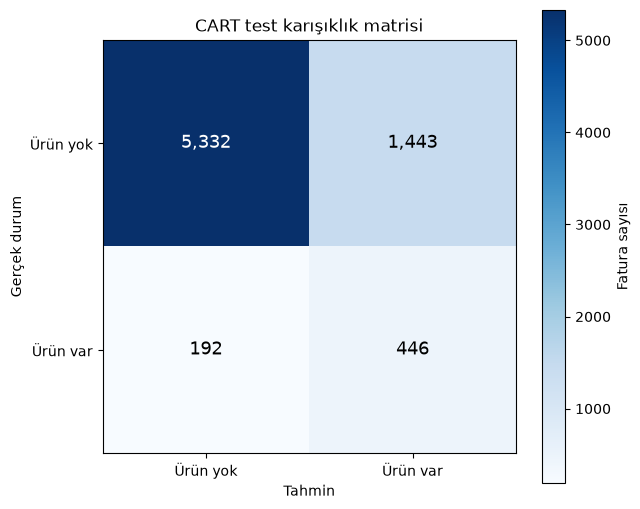

In [11]:
cm = np.asarray(classification['cart']['test']['confusion_matrix'])
fig, ax = plt.subplots(figsize=(6.5, 5.5))
image = ax.imshow(cm, cmap='Blues')
for row in range(cm.shape[0]):
    for column in range(cm.shape[1]):
        ax.text(column, row, f'{cm[row, column]:,}', ha='center', va='center',
                color='white' if cm[row, column] > cm.max() / 2 else 'black', fontsize=13)
ax.set(xticks=[0, 1], yticks=[0, 1], xticklabels=['Ürün yok', 'Ürün var'],
       yticklabels=['Ürün yok', 'Ürün var'], xlabel='Tahmin', ylabel='Gerçek durum',
       title='CART test karışıklık matrisi')
fig.colorbar(image, ax=ax, label='Fatura sayısı')
fig.tight_layout()
fig.savefig(FIGURES / '09_cart_confusion.jpeg', dpi=170, pil_kwargs={'quality': 95, 'subsampling': 0})
plt.show()


## ROC eğrisi

Kesikli çizgi, sabit çoğunluk tahmininin ayırt etme düzeyini gösterir.


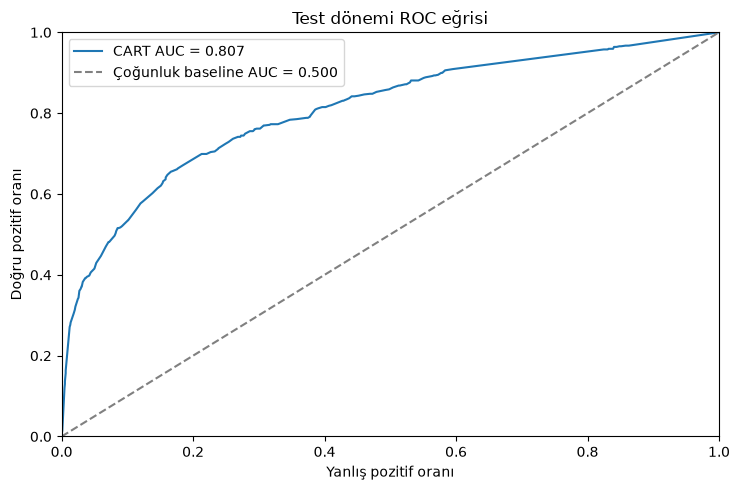

In [12]:
fig, ax = plt.subplots(figsize=(7.5, 5))
ax.plot(fpr, tpr, label=f"CART AUC = {classification['cart']['test']['roc_auc']:.3f}")
ax.plot([0, 1], [0, 1], linestyle='--', color='gray', label='Çoğunluk baseline AUC = 0.500')
ax.set(xlabel='Yanlış pozitif oranı', ylabel='Doğru pozitif oranı', title='Test dönemi ROC eğrisi',
       xlim=(0, 1), ylim=(0, 1))
ax.legend()
fig.tight_layout()
fig.savefig(FIGURES / '10_cart_roc.jpeg', dpi=170, pil_kwargs={'quality': 95, 'subsampling': 0})
plt.show()


## Precision–recall eğrisi

Baseline average precision değeri testteki hedef ürün oranına eşittir. ROC-AUC ile aynı ölçüt değildir.


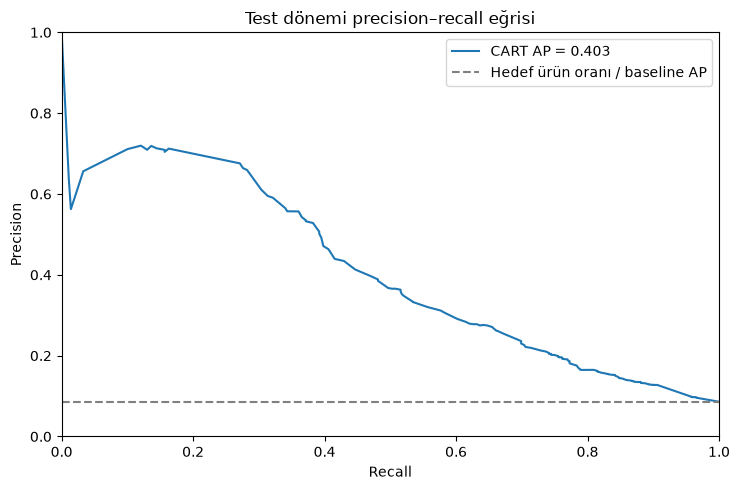

In [13]:
fig, ax = plt.subplots(figsize=(7.5, 5))
ax.plot(recall, precision, label=f"CART AP = {classification['cart']['test']['average_precision']:.3f}")
ax.axhline(float(ytest.mean()), linestyle='--', color='gray', label='Hedef ürün oranı / baseline AP')
ax.set(xlabel='Recall', ylabel='Precision', title='Test dönemi precision–recall eğrisi',
       xlim=(0, 1), ylim=(0, 1))
ax.legend()
fig.tight_layout()
fig.savefig(FIGURES / '11_cart_pr.jpeg', dpi=170, pil_kwargs={'quality': 95, 'subsampling': 0})
plt.show()


## Ağacın okunması

`feature <= 0.5` ürünün bulunmadığı, `feature > 0.5` bulunduğu dalı ifade eder. Uzun ağaç gösterimi ilk sekiz derinlikle sınırlandırılır; bu, kaydedilen modelin derinlik ayarını değiştirmez.


In [14]:
print(classification['tree_text'])


|--- 21733 <= 0.50
|   |--- 82494L <= 0.50
|   |   |--- 22189 <= 0.50
|   |   |   |--- 21755 <= 0.50
|   |   |   |   |--- 22464 <= 0.50
|   |   |   |   |   |--- 84879 <= 0.50
|   |   |   |   |   |   |--- 84836 <= 0.50
|   |   |   |   |   |   |   |--- 21232 <= 0.50
|   |   |   |   |   |   |   |   |--- 22469 <= 0.50
|   |   |   |   |   |   |   |   |   |--- truncated branch of depth 98
|   |   |   |   |   |   |   |   |--- 22469 >  0.50
|   |   |   |   |   |   |   |   |   |--- truncated branch of depth 4
|   |   |   |   |   |   |   |--- 21232 >  0.50
|   |   |   |   |   |   |   |   |--- 84520B <= 0.50
|   |   |   |   |   |   |   |   |   |--- truncated branch of depth 10
|   |   |   |   |   |   |   |   |--- 84520B >  0.50
|   |   |   |   |   |   |   |   |   |--- class: 1
|   |   |   |   |   |   |--- 84836 >  0.50
|   |   |   |   |   |   |   |--- 84970L <= 0.50
|   |   |   |   |   |   |   |   |--- 22470 <= 0.50
|   |   |   |   |   |   |   |   |   |--- class: 1
|   |   |   |   |   |   |   |  